

**Goal:** take one ~1-second EEG segment (178 numbers) and predict *seizure* (1) or *non-seizure* (0),
so a clinician can look at the flagged segments first. The clinician always makes the final decision.

> This is an educational exercise. The model is **not** a diagnostic tool and is **not** ready for clinical use.

**How to run:** put `Epileptic Seizure Recognition.csv` in the same folder as this notebook, then *Kernel → Restart & Run All*.
Needs pandas, NumPy, scikit-learn and matplotlib. Runs on a normal laptop CPU in about a minute.

## Part A — Load, check, and define the target

In [1]:
# ---------- Setup ----------
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42                      # one fixed seed for every split and model
np.random.seed(SEED)
os.makedirs("figures", exist_ok=True)

# Data source: Kaggle "Epileptic Seizure Recognition" — a reshaped CSV of the
# Bonn EEG dataset (Andrzejak et al., 2001, Physical Review E 64, 061907).
# Keep the CSV next to this notebook, or point DATA_PATH at the course copy:
#   "module2/lectures/data/Epileptic Seizure Recognition.csv"
DATA_PATH = "Epileptic Seizure Recognition.csv"

df = pd.read_csv(DATA_PATH)
df = df.rename(columns={df.columns[0]: "segment_id"}).copy()   # first column = segment identifier

print("Shape:", df.shape)
print("Missing values:", df.isna().sum().sum())
print("\nRows per original label y:")
print(df["y"].value_counts().sort_index())

Shape: (11500, 180)
Missing values: 0

Rows per original label y:
y
1    2300
2    2300
3    2300
4    2300
5    2300
Name: count, dtype: int64


In [2]:
# ---------- Recording ID ----------
# "X21.V1.791" -> chunk number "X21" and recording ID "V1.791"
df["recording_id"] = df["segment_id"].str.split(".", n=1).str[1]

print("Number of recordings:", df["recording_id"].nunique())
print("Rows per recording:", df.groupby("recording_id").size().unique())
print("Most labels found inside one recording:", df.groupby("recording_id")["y"].nunique().max())

Number of recordings: 500
Rows per recording: [23]
Most labels found inside one recording: 1


In [3]:
# ---------- Binary target ----------
df["seizure"] = (df["y"] == 1).astype(int)     # 1 = seizure, 0 = labels 2,3,4,5

signal_cols = [f"X{i}" for i in range(1, 179)]  # the 178 signal values

n_pos = df["seizure"].sum()
print(f"Seizure rows: {n_pos} of {len(df)} ({100 * n_pos / len(df):.1f}%)")
print(f"Accuracy of always predicting 'non-seizure': {100 * (1 - df['seizure'].mean()):.1f}%")

Seizure rows: 2300 of 11500 (20.0%)
Accuracy of always predicting 'non-seizure': 80.0%


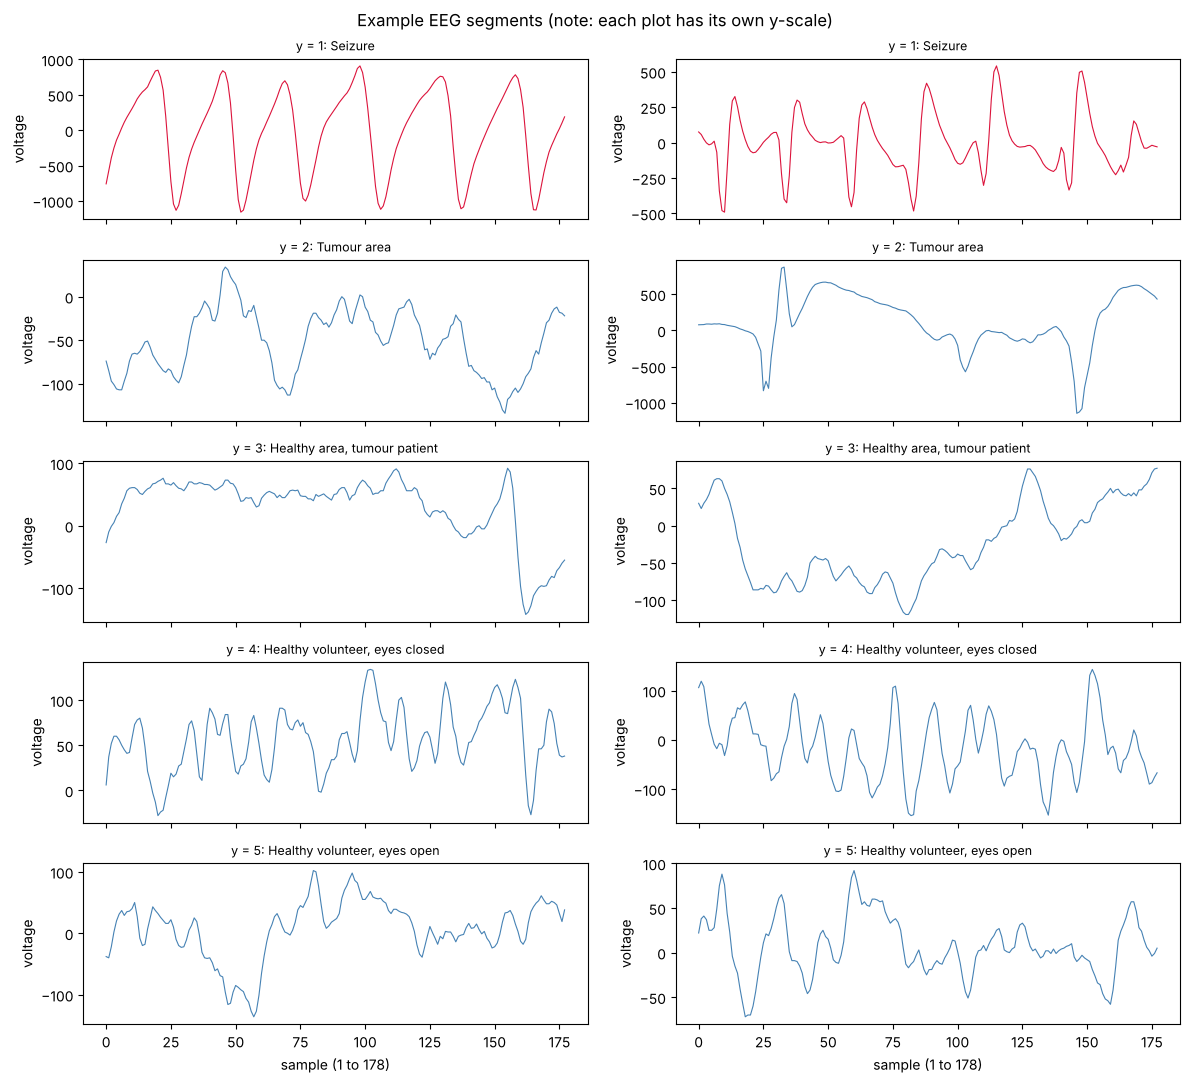

In [4]:
# ---------- Plot 2 example segments for each label ----------
label_names = {1: "Seizure", 2: "Tumour area", 3: "Healthy area, tumour patient",
               4: "Healthy volunteer, eyes closed", 5: "Healthy volunteer, eyes open"}

fig, axes = plt.subplots(5, 2, figsize=(12, 11), sharex=True)
for i, label in enumerate(range(1, 6)):
    examples = df[df["y"] == label].sample(2, random_state=SEED)
    for j in range(2):
        axes[i, j].plot(examples.iloc[j][signal_cols].values, lw=0.8,
                        color="crimson" if label == 1 else "steelblue")
        axes[i, j].set_title(f"y = {label}: {label_names[label]}", fontsize=9)
        axes[i, j].set_ylabel("voltage")
axes[-1, 0].set_xlabel("sample (1 to 178)")
axes[-1, 1].set_xlabel("sample (1 to 178)")
plt.suptitle("Example EEG segments (note: each plot has its own y-scale)")
plt.tight_layout()
plt.savefig("figures/segments.png", dpi=150)
plt.show()

### Part A answers

**What is one row, one recording, and one person?**
- **Row** = one segment: 178 voltage values, about 1 second of single-channel EEG.
- **Recording** = 23 consecutive segments cut from one ~23.6-second EEG recording. There are 500 recordings (100 per label), and every recording has only one label.
- **Person** = the human the recording came from. The original Bonn study used only a small number of people (the paper describes five healthy volunteers and five patients), so many recordings come from the same person. The CSV has **no patient ID**, so we cannot split by person.

**What accuracy would "always non-seizure" get?** **80%**, because 80% of rows are non-seizure. That model catches **zero** seizures, so a high accuracy can hide a useless model. That is why we report sensitivity, specificity, PPV, NPV and AUC instead.

**Why does 20% seizure rows not tell us how common seizures are in real EEG?** The dataset designers *chose* 100 recordings per label, so the 20% is a design choice. In a real long EEG recording, seizures are usually a tiny fraction of the time. With fewer real seizures, the same model would give a much lower PPV (more false alarms per true seizure).

## Part B — Split without leakage
We split by **recording ID**, not by row: all 23 segments of a recording go to the same set.
`StratifiedGroupKFold` keeps the groups together and keeps the seizure % about the same in each set.

In [5]:
# ---------- Split by recording (no leakage) ----------
from sklearn.model_selection import StratifiedGroupKFold

# Step 1: keep ~20% of recordings aside as the TEST set
split1 = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
trainval_idx, test_idx = next(split1.split(df, df["seizure"], groups=df["recording_id"]))
trainval, test = df.iloc[trainval_idx], df.iloc[test_idx]

# Step 2: split the other 80% into TRAIN (~60% overall) and VALIDATION (~20% overall)
split2 = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEED)
train_idx, val_idx = next(split2.split(trainval, trainval["seizure"], groups=trainval["recording_id"]))
train, val = trainval.iloc[train_idx], trainval.iloc[val_idx]

# Check: no recording appears in two sets
tr, va, te = set(train["recording_id"]), set(val["recording_id"]), set(test["recording_id"])
print("Overlap train-val:", len(tr & va), "| train-test:", len(tr & te), "| val-test:", len(va & te))

split_summary = pd.DataFrame({
    "rows": [len(s) for s in (train, val, test)],
    "recordings": [s["recording_id"].nunique() for s in (train, val, test)],
    "seizure %": [round(100 * s["seizure"].mean(), 1) for s in (train, val, test)],
}, index=["train", "validation", "test"])
split_summary

Overlap train-val: 0 | train-test: 0 | val-test: 0


,rows,recordings,seizure %
train,6900,300,20.0
validation,2300,100,20.0
test,2300,100,20.0


**Result:** 300 / 100 / 100 recordings (60% / 20% / 20%), 20% seizure in each set, and **zero recordings shared** between sets.
The scaler is put inside a scikit-learn `Pipeline` in Part C, so it is fitted on the **training set only**.

### Part B answer — how could a random row split leak information?
Neighbouring segments of the same recording are very alike: same person, same electrode, same noise and amplitude level.
With a random row split, some segments of a recording go to training and others to test. The model can then
"recognise the recording" instead of learning what a seizure looks like. The test set stops being truly new data,
so test performance looks **better than it would on a new recording or a new patient**.

We use the **validation set** to compare models and choose the threshold. The **test set is used only once**, in Part E.

## Part C — Baseline and comparison models
Two kinds of input:
1. **Raw signal** — the 178 values as they are.
2. **Engineered features** — 8 simple numbers per segment: mean, standard deviation, min, max, range (peak-to-peak),
   energy (sum of squares), zero-crossing count (how often the signal crosses its own mean), and line length (sum of absolute jumps between neighbouring values).

In [6]:
# ---------- Engineered features (8 simple numbers per segment) ----------
def make_features(data):
    X = data[signal_cols].values.astype(float)
    centred = X - X.mean(axis=1, keepdims=True)          # remove offset before counting crossings
    return pd.DataFrame({
        "mean": X.mean(axis=1),
        "std": X.std(axis=1),
        "min": X.min(axis=1),
        "max": X.max(axis=1),
        "range": X.max(axis=1) - X.min(axis=1),            # peak-to-peak
        "energy": (X ** 2).sum(axis=1),
        "zero_crossings": (np.diff(np.sign(centred), axis=1) != 0).sum(axis=1),
        "line_length": np.abs(np.diff(X, axis=1)).sum(axis=1),
    })

inputs = {
    "raw":      {s: d[signal_cols].values for s, d in (("train", train), ("val", val), ("test", test))},
    "features": {s: make_features(d).values for s, d in (("train", train), ("val", val), ("test", test))},
}
feature_names = list(make_features(train.head(1)).columns)
y_train, y_val, y_test = train["seizure"].values, val["seizure"].values, test["seizure"].values
make_features(train).head()

,mean,std,min,max,range,energy,zero_crossings,line_length
0,28.112360,471.835823,-1716.0,513.0,2229.0,39768644.0,8,14039.0
1,-68.910112,15.923723,-105.0,-22.0,83.0,890386.0,31,1072.0
2,-6.651685,38.693001,-103.0,78.0,181.0,274368.0,28,2738.0
3,13.988764,64.883300,-137.0,141.0,278.0,784184.0,21,3753.0
4,-32.544944,37.104782,-118.0,39.0,157.0,433597.0,3,858.0


Models: **logistic regression on raw values (baseline)**, random forest and gradient boosting on raw values,
and logistic regression and random forest on the engineered features.

In [7]:
# ---------- Train the models ----------
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

# The scaler sits inside a pipeline, so it is fitted on the TRAINING data only.
models = {
    "LogReg raw (baseline)": (make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=SEED)), "raw"),
    "RandomForest raw":      (RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1), "raw"),
    "GradBoost raw":         (HistGradientBoostingClassifier(random_state=SEED), "raw"),
    "LogReg features":       (make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=SEED)), "features"),
    "RandomForest features": (RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1), "features"),
}

val_probs = {}
for name, (model, kind) in models.items():
    model.fit(inputs[kind]["train"], y_train)
    val_probs[name] = model.predict_proba(inputs[kind]["val"])[:, 1]   # P(seizure)
    print("trained:", name)

trained: LogReg raw (baseline)


trained: RandomForest raw


trained: GradBoost raw
trained: LogReg features


trained: RandomForest features


### Part C answers *(numbers come from the validation table in Part D)*

**Raw values or engineered features — which worked better?** Engineered features. Same random forest: PR-AUC **0.979 with features vs 0.971 raw**.
The biggest jump is logistic regression: ROC-AUC **0.504 on raw values (no better than a coin flip) vs 0.993 on features**.

*Possible reason:* each segment starts at an arbitrary moment, so "value number 37" means nothing on its own.
Seizure information is in the **size and shape** of the waves (large amplitude, lots of fast high jumps), which can appear anywhere in the segment.
A linear model on raw values cannot see that; the features summarise it regardless of position. Trees do better on raw values because they can pick up extreme values, but the features still help.

**Which features are easiest to explain to a clinician?** **Range** (how tall the waves are), **standard deviation** (how much the signal swings),
and **line length** (how long the trace would be if you stretched it out — big, fast waves give a long line). Zero crossings roughly match how fast the waves are. Energy is harder to picture.

## Part D — Evaluate on the validation set
- **Sensitivity** = of real seizure segments, how many we caught.  **Specificity** = of non-seizure segments, how many we correctly left alone.
- **PPV** = of flagged segments, how many really are seizure.  **NPV** = of segments we did not flag, how many really are non-seizure.
- **ROC-AUC / PR-AUC** = how well the model ranks seizure above non-seizure across all thresholds.  **Brier score** = average squared error of the probabilities (lower is better).

In [8]:
# ---------- Metrics ----------
from sklearn.metrics import (confusion_matrix, roc_auc_score, average_precision_score,
                             brier_score_loss, roc_curve)

def evaluate(y_true, prob, threshold=0.5):
    pred = (prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {
        "threshold": round(threshold, 3), "TP": tp, "FP": fp, "TN": tn, "FN": fn,
        "Sensitivity": tp / (tp + fn), "Specificity": tn / (tn + fp),
        "PPV": tp / (tp + fp) if tp + fp else np.nan,
        "NPV": tn / (tn + fn) if tn + fn else np.nan,
        "ROC-AUC": roc_auc_score(y_true, prob),
        "PR-AUC": average_precision_score(y_true, prob),
        "Brier": brier_score_loss(y_true, prob),
    }

val_table = pd.DataFrame({name: evaluate(y_val, p) for name, p in val_probs.items()}).T
val_table.round(3)

,threshold,TP,FP,TN,FN,Sensitivity,Specificity,PPV,NPV,ROC-AUC,PR-AUC,Brier
LogReg raw (baseline),0.5,69.0,4.0,1836.0,391.0,0.150,0.998,0.945,0.824,0.504,0.453,0.150
RandomForest raw,0.5,401.0,24.0,1816.0,59.0,0.872,0.987,0.944,0.969,0.989,0.971,0.030
GradBoost raw,0.5,398.0,16.0,1824.0,62.0,0.865,0.991,0.961,0.967,0.992,0.977,0.026
LogReg features,0.5,382.0,13.0,1827.0,78.0,0.830,0.993,0.967,0.959,0.993,0.979,0.027
RandomForest features,0.5,410.0,11.0,1829.0,50.0,0.891,0.994,0.974,0.973,0.991,0.979,0.021


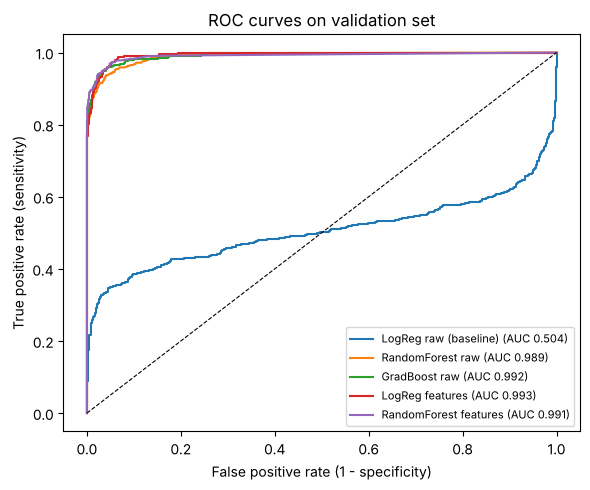

In [9]:
# ---------- ROC curves ----------
plt.figure(figsize=(6, 5))
for name, p in val_probs.items():
    fpr, tpr, _ = roc_curve(y_val, p)
    plt.plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_val, p):.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=0.8)
plt.xlabel("False positive rate (1 - specificity)")
plt.ylabel("True positive rate (sensitivity)")
plt.title("ROC curves on validation set")
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig("figures/roc.png", dpi=150)
plt.show()

Best model on validation (by PR-AUC): RandomForest features


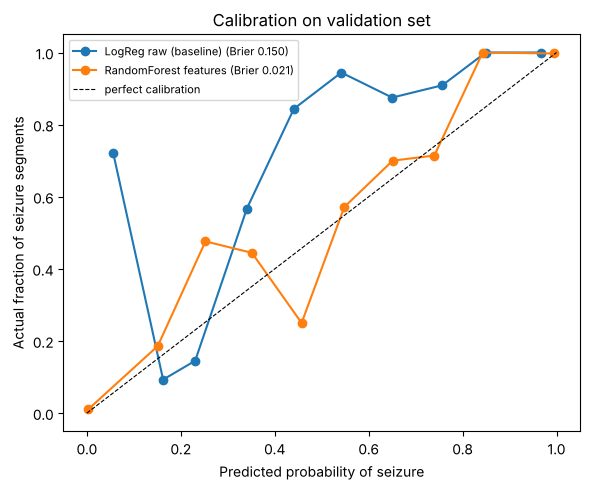

In [10]:
# ---------- Pick the best model and check calibration ----------
from sklearn.calibration import calibration_curve

best_name = val_table["PR-AUC"].astype(float).idxmax()     # best at ranking seizure segments
baseline_name = "LogReg raw (baseline)"
print("Best model on validation (by PR-AUC):", best_name)

plt.figure(figsize=(6, 5))
for name in [baseline_name, best_name]:
    frac_pos, mean_pred = calibration_curve(y_val, val_probs[name], n_bins=10)
    plt.plot(mean_pred, frac_pos, "o-", label=f"{name} (Brier {brier_score_loss(y_val, val_probs[name]):.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=0.8, label="perfect calibration")
plt.xlabel("Predicted probability of seizure")
plt.ylabel("Actual fraction of seizure segments")
plt.title("Calibration on validation set")
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig("figures/calibration.png", dpi=150)
plt.show()

**Calibration:** the baseline's Brier score is 0.150 and its curve is far from the diagonal — its probabilities mean little (for example, segments it gave ~5% actually contained mostly seizures).
The random forest on features has Brier 0.021 and roughly follows the diagonal. The middle bins are noisy because few segments get mid-range probabilities.
The best model is chosen by PR-AUC; logistic regression on features is essentially tied (0.979), so either would be a reasonable choice.

### Threshold choice
**Rule:** the **highest threshold that still gives at least 95% sensitivity** on the validation set.

In [11]:
# ---------- Choose a threshold ----------
# Rule: the HIGHEST threshold that still gives at least 95% sensitivity on validation.
def threshold_for_sensitivity(y_true, prob, target=0.95):
    for t in np.sort(np.unique(prob))[::-1]:          # try thresholds from high to low
        if evaluate(y_true, prob, t)["Sensitivity"] >= target:
            return t

chosen_threshold = threshold_for_sensitivity(y_val, val_probs[best_name])
print(f"Chosen threshold for {best_name}: {chosen_threshold:.3f}")
pd.Series(evaluate(y_val, val_probs[best_name], chosen_threshold)).round(3)

Chosen threshold for RandomForest features: 0.160


threshold         0.160
TP              437.000
FP               65.000
TN             1775.000
FN               23.000
Sensitivity       0.950
Specificity       0.965
PPV               0.871
NPV               0.987
ROC-AUC           0.991
PR-AUC            0.979
Brier             0.021
dtype: float64

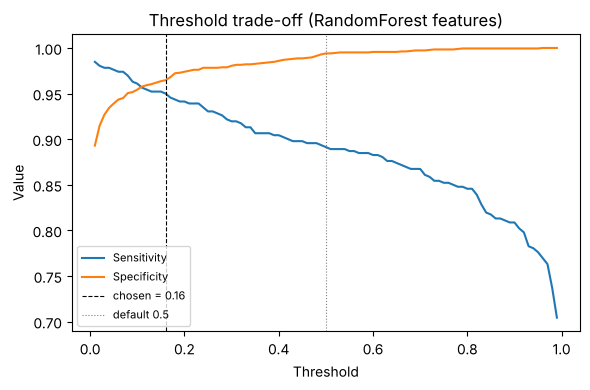

In [12]:
# ---------- Sensitivity / specificity vs threshold ----------
ts = np.linspace(0.01, 0.99, 99)
sens = [evaluate(y_val, val_probs[best_name], t)["Sensitivity"] for t in ts]
spec = [evaluate(y_val, val_probs[best_name], t)["Specificity"] for t in ts]
plt.figure(figsize=(6, 4))
plt.plot(ts, sens, label="Sensitivity")
plt.plot(ts, spec, label="Specificity")
plt.axvline(chosen_threshold, color="k", ls="--", lw=0.8, label=f"chosen = {chosen_threshold:.2f}")
plt.axvline(0.5, color="grey", ls=":", lw=0.8, label="default 0.5")
plt.xlabel("Threshold"); plt.ylabel("Value"); plt.title(f"Threshold trade-off ({best_name})")
plt.legend(fontsize=8); plt.tight_layout()
plt.savefig("figures/threshold.png", dpi=150)
plt.show()

In [13]:
# ---------- Same rule applied to every model: does higher ROC-AUC always win? ----------
rows = {}
for name, p in val_probs.items():
    t = threshold_for_sensitivity(y_val, p)
    r = evaluate(y_val, p, t)
    rows[name] = {"ROC-AUC": r["ROC-AUC"], "threshold": r["threshold"], "Sensitivity": r["Sensitivity"],
                  "FP": r["FP"], "Specificity": r["Specificity"], "PPV": r["PPV"]}
pd.DataFrame(rows).T.sort_values("ROC-AUC", ascending=False).round(3)

,ROC-AUC,threshold,Sensitivity,FP,Specificity,PPV
LogReg features,0.993,0.136,0.95,64.0,0.965,0.872
GradBoost raw,0.992,0.044,0.95,73.0,0.960,0.857
RandomForest features,0.991,0.160,0.95,65.0,0.965,0.871
RandomForest raw,0.989,0.210,0.95,109.0,0.941,0.800
LogReg raw (baseline),0.504,0.016,0.95,1839.0,0.001,0.192


### Part D answers

**Is a missed seizure or a false alarm more costly?** In this workflow the tool only decides **what the clinician looks at first**.
A false alarm costs a few seconds of review. A missed seizure may be pushed down the queue and reviewed late or not at all. So a **miss is more costly**.
That is why the rule asks for at least 95% sensitivity. The threshold falls from 0.5 to **0.16**: missed seizure segments drop from **50 to 23**, while false positives rise from **11 to 65** (out of 1,840 non-seizure segments).

**If the tool flagged 100 segments, how many would be real seizures?** About **87** (validation PPV 0.871; test PPV 0.857 gives about 86). **PPV** answers this question.
Warning: PPV depends on how common seizures are. Here they are 20% of rows; in real EEG they are rarer, so PPV would be lower.

**Does a higher ROC-AUC always give better results at the chosen threshold?** **No.** ROC-AUC averages over all thresholds, but we only use one.
Gradient boosting has a higher ROC-AUC than the random forest on features (0.992 vs 0.991), yet at 95% sensitivity it gives **73 false positives vs 65**.
What matters is performance at the operating point.

## Part E — Final test (used once) and error analysis
Selected model: **random forest on engineered features**, threshold **0.16** (both chosen on validation only).

In [14]:
# ---------- FINAL TEST (used once) ----------
best_model, best_kind = models[best_name]
test_prob = best_model.predict_proba(inputs[best_kind]["test"])[:, 1]
test_pred = (test_prob >= chosen_threshold).astype(int)
test_result = evaluate(y_test, test_prob, chosen_threshold)
pd.Series(test_result).round(3)

threshold         0.160
TP              449.000
FP               75.000
TN             1765.000
FN               11.000
Sensitivity       0.976
Specificity       0.959
PPV               0.857
NPV               0.994
ROC-AUC           0.994
PR-AUC            0.976
Brier             0.025
dtype: float64

In [15]:
# ---------- Bootstrap 95% CI (resample RECORDINGS, not rows) ----------
rng = np.random.default_rng(SEED)
test_recs = test["recording_id"].values
unique_recs = np.unique(test_recs)
rows_of = {r: np.where(test_recs == r)[0] for r in unique_recs}

boot_sens, boot_spec = [], []
for _ in range(1000):
    sample = rng.choice(unique_recs, size=len(unique_recs), replace=True)
    idx = np.concatenate([rows_of[r] for r in sample])
    yt, yp = y_test[idx], test_pred[idx]
    boot_sens.append(((yp == 1) & (yt == 1)).sum() / (yt == 1).sum())
    boot_spec.append(((yp == 0) & (yt == 0)).sum() / (yt == 0).sum())

print(f"Sensitivity {test_result['Sensitivity']:.3f}  95% CI [{np.percentile(boot_sens, 2.5):.3f}, {np.percentile(boot_sens, 97.5):.3f}]")
print(f"Specificity {test_result['Specificity']:.3f}  95% CI [{np.percentile(boot_spec, 2.5):.3f}, {np.percentile(boot_spec, 97.5):.3f}]")

Sensitivity 0.976  95% CI [0.941, 1.000]
Specificity 0.959  95% CI [0.923, 0.989]


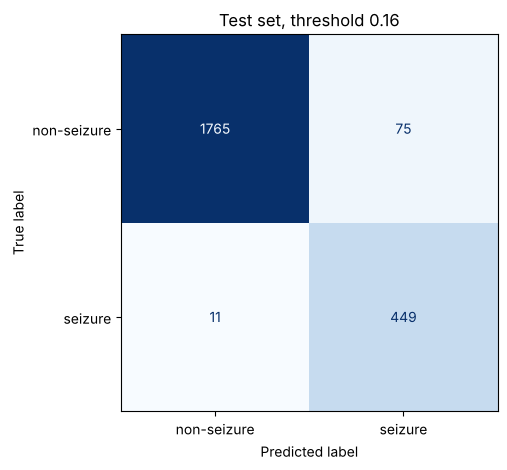

In [16]:
# ---------- Confusion matrix plot ----------
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(y_test, test_pred, display_labels=["non-seizure", "seizure"],
                                        cmap="Blues", colorbar=False)
plt.title(f"Test set, threshold {chosen_threshold:.2f}")
plt.tight_layout()
plt.savefig("figures/test_confusion.png", dpi=150)
plt.show()

error                              correct  false negative  false positive
1: Seizure                             449              11               0
2: Tumour area                         409               0              28
3: Healthy area, tumour patient        271               0              28
4: Healthy volunteer, eyes closed      602               0              19
5: Healthy volunteer, eyes open        483               0               0


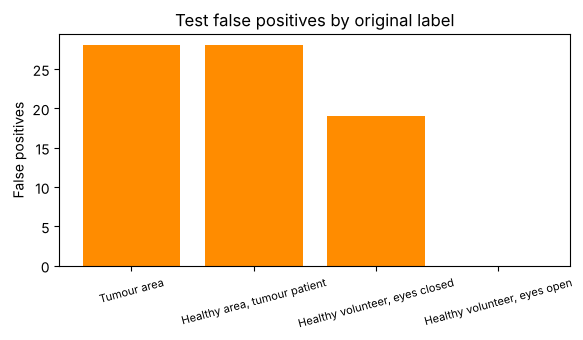

In [17]:
# ---------- Errors by original label ----------
results = test[["recording_id", "y", "seizure"]].copy()
results["prob"], results["pred"] = test_prob, test_pred
results["error"] = np.where((results.pred == 1) & (results.seizure == 0), "false positive",
                   np.where((results.pred == 0) & (results.seizure == 1), "false negative", "correct"))

errors_by_label = pd.crosstab(results["y"], results["error"])
errors_by_label.index = [f"{y}: {label_names[y]}" for y in errors_by_label.index]
print(errors_by_label)

fp_counts = results[results.error == "false positive"]["y"].value_counts().reindex([2, 3, 4, 5], fill_value=0)
plt.figure(figsize=(6, 3.5))
plt.bar([label_names[y] for y in fp_counts.index], fp_counts.values, color="darkorange")
plt.ylabel("False positives"); plt.title("Test false positives by original label")
plt.xticks(rotation=15, fontsize=8); plt.tight_layout()
plt.savefig("figures/fp_by_label.png", dpi=150)
plt.show()

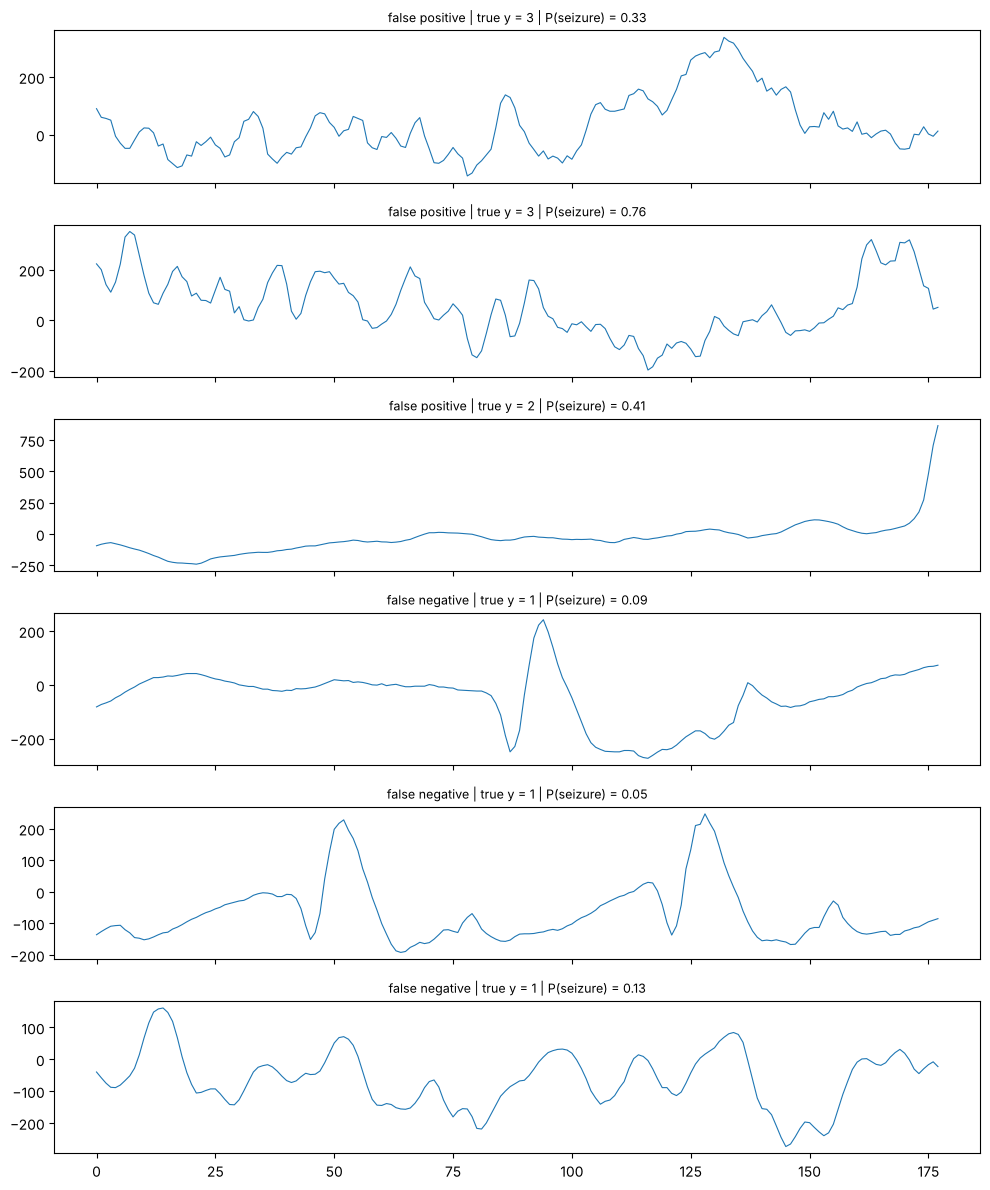

In [18]:
# ---------- Plot a few mistakes ----------
fp_rows = results[results.error == "false positive"].head(3)
fn_rows = results[results.error == "false negative"].head(3)
examples = pd.concat([fp_rows, fn_rows])
if len(examples):
    fig, axes = plt.subplots(len(examples), 1, figsize=(10, 2 * len(examples)), sharex=True, squeeze=False)
    for ax, (idx, row) in zip(axes[:, 0], examples.iterrows()):
        ax.plot(test.loc[idx, signal_cols].values, lw=0.8)
        ax.set_title(f"{row.error} | true y = {row.y} | P(seizure) = {row.prob:.2f}", fontsize=9)
    plt.tight_layout(); plt.show()

In [19]:
# ---------- Do mistakes cluster in some recordings? ----------
errors_per_rec = results.assign(wrong=results.error != "correct").groupby("recording_id")["wrong"].sum()
print("Test recordings:", len(errors_per_rec))
print("Recordings with no mistakes:", (errors_per_rec == 0).sum())
print("Recordings with 1+ mistakes:", (errors_per_rec > 0).sum())
print("Total mistakes:", errors_per_rec.sum())
print("\nRecordings with the most mistakes (out of 23 segments):")
worst = errors_per_rec.sort_values(ascending=False).head(5)
rec_label = results.groupby("recording_id")["y"].first()
print(pd.DataFrame({"mistakes": worst, "true y": rec_label[worst.index]}))

Test recordings: 100
Recordings with no mistakes: 85
Recordings with 1+ mistakes: 15
Total mistakes: 86

Recordings with the most mistakes (out of 23 segments):
              mistakes  true y
recording_id                  
V1.723              23       2
V1.412              20       3
V1.492               8       3
V1.317               7       1
V1.161               6       4


In [20]:
# ---------- Recording-level decision ----------
# A recording is flagged if at least k of its 23 segments are predicted seizure.
rec = results.groupby("recording_id").agg(seizure=("seizure", "first"), n_flagged=("pred", "sum"))
rec_rows = []
for k in [1, 2, 3, 5]:
    flag = (rec["n_flagged"] >= k).astype(int)
    tp = ((flag == 1) & (rec.seizure == 1)).sum(); fn = ((flag == 0) & (rec.seizure == 1)).sum()
    tn = ((flag == 0) & (rec.seizure == 0)).sum(); fp = ((flag == 1) & (rec.seizure == 0)).sum()
    rec_rows.append({"k": k, "TP": tp, "FN": fn, "TN": tn, "FP": fp,
                     "Sensitivity": tp / (tp + fn), "Specificity": tn / (tn + fp)})
rec_table = pd.DataFrame(rec_rows).set_index("k")
print("Segment level: sensitivity", round(test_result["Sensitivity"], 3), "| specificity", round(test_result["Specificity"], 3))
rec_table.round(3)

Segment level: sensitivity 0.976 | specificity 0.959


,TP,FN,TN,FP,Sensitivity,Specificity
k,,,,,,
1,20,0,68,12,1.0,0.850
2,20,0,72,8,1.0,0.900
3,20,0,73,7,1.0,0.912
5,20,0,75,5,1.0,0.938


### Part E answers

**Test result:** sensitivity **0.976** (95% CI 0.941–1.000) and specificity **0.959** (95% CI 0.923–0.989), with bootstrap resampling of recordings.
These are close to validation, so the threshold carried over well. The intervals are wide because there are only 100 test recordings (20 with seizures).

**Which non-seizure label produced the most false positives?** **Label 2 (tumour area) and label 3 (healthy area in a tumour patient), with 28 each**, then label 4 (eyes closed, 19). Label 5 (eyes open) gave **none**.
*Why:* labels 2 and 3 come from patients, whose EEG between seizures can still contain sharp, high-amplitude activity that looks seizure-like.
Eyes-closed EEG has stronger, rhythmic alpha waves. Eyes-open EEG is low-amplitude and calm, so it is easy to tell apart.

**Do mistakes cluster in particular recordings?** **Yes, strongly.** All 86 test mistakes are in just **15 of 100 recordings**, and the worst two recordings alone have **23 and 20** of their 23 segments wrong (both from tumour patients, labels 2 and 3).
This suggests the errors are about *the recording or the person* (their background EEG, electrode, artefacts), not random segment-level noise.
So segments are not independent, and a model that does well on these people may fail on a new person.

**Recording-level decision:** with "flag if at least 1 segment is positive", recording sensitivity is **100%** (all 20 seizure recordings caught) but specificity drops to **85%** (12 healthy recordings flagged), because one stray positive out of 23 is enough.
Requiring **at least 5** positive segments keeps sensitivity at 100% and raises specificity to **93.8%**.

## Final results table
All models on validation at the default 0.5 threshold, plus the selected model at the chosen threshold on validation and on the test set.

In [21]:
# ---------- Final results table ----------
final = val_table.copy()
final.index = [f"{n} | validation | t=0.5" for n in final.index]
final.loc[f"{best_name} | validation | t={chosen_threshold:.2f}"] = evaluate(y_val, val_probs[best_name], chosen_threshold)
final.loc[f"{best_name} | TEST | t={chosen_threshold:.2f}"] = test_result
final = final[["threshold", "TP", "FP", "TN", "FN", "Sensitivity", "Specificity", "PPV", "NPV", "ROC-AUC", "PR-AUC", "Brier"]]
final.to_csv("figures/final_results.csv")
final.astype(float).round(3)

,threshold,TP,FP,TN,FN,Sensitivity,Specificity,PPV,NPV,ROC-AUC,PR-AUC,Brier
LogReg raw (baseline) | validation | t=0.5,0.50,69.0,4.0,1836.0,391.0,0.150,0.998,0.945,0.824,0.504,0.453,0.150
RandomForest raw | validation | t=0.5,0.50,401.0,24.0,1816.0,59.0,0.872,0.987,0.944,0.969,0.989,0.971,0.030
GradBoost raw | validation | t=0.5,0.50,398.0,16.0,1824.0,62.0,0.865,0.991,0.961,0.967,0.992,0.977,0.026
LogReg features | validation | t=0.5,0.50,382.0,13.0,1827.0,78.0,0.830,0.993,0.967,0.959,0.993,0.979,0.027
RandomForest features | validation | t=0.5,0.50,410.0,11.0,1829.0,50.0,0.891,0.994,0.974,0.973,0.991,0.979,0.021
RandomForest features | validation | t=0.16,0.16,437.0,65.0,1775.0,23.0,0.950,0.965,0.871,0.987,0.991,0.979,0.021
RandomForest features | TEST | t=0.16,0.16,449.0,75.0,1765.0,11.0,0.976,0.959,0.857,0.994,0.994,0.976,0.025


## Part F — Reflection

These results look excellent, but they do not show the tool is clinically useful. The 500 recordings come from only about ten people, so the model may have learned those people's EEG rather than seizures in general; the error clustering in Part E supports this concern. Each sample is a single channel, while hospital EEG uses many channels, and the segments were pre-selected by the original researchers to be clean and clear-cut — real recordings contain muscle and movement artefacts, sleep, and borderline events. The classes are balanced by design (20% seizure), whereas seizures are rare in real monitoring, which would lower PPV and increase false alarms. The model also ignores clinical context such as medication, age and video of the patient.

Before any hospital use, the model would need external validation: testing on new patients from other hospitals and EEG machines, on full continuous multichannel recordings, with a person-level split and seizure labels from several independent experts. It should then be tested prospectively, comparing review time and missed seizures with and without the tool.

In practice, the tool should only reorder the review queue for a trained neurologist or EEG technologist, who makes every decision. To avoid alert fatigue, it should flag whole time windows rather than every one-second segment (for example, require several positive segments, as in Part E), show the probability and the reason (such as high amplitude or line length), and have its threshold and false-alarm rate monitored over time.